# Post-buckling of an axially compressed cylinder with imperfections

Simo, Fox and Rifai [1], Section 6.3.4 (pp. 54-57, Fig. 6.3.4 on p. 56),
traced the post-buckling path of a simply supported cylinder under axial
compression, with and without an initial geometric imperfection, with the
Riks method and their geometrically exact shell element: radius $R = 36$,
length $L = 100$, thickness $t = 0.125$, $E = 10^7$, $\nu = 0.3$. As in
Stanley [2], they modelled an $L/10 \times 15°$ section of the cylinder,
with symmetry conditions on the interior edges and a simple support on the
loaded edge, with a $10 \times 10$ mesh, such that the post-buckling path is
that of the diamond mode of 5 axial half-waves and 12 circumferential
waves. The imperfections, of 10 % and 50 % of the thickness, have the shape
of the lowest linear buckling mode; the loads are normalized by the linear
buckling load and plotted against the axial deflection of the loaded edge,
its maximum in Fig. 6.3.4(a) and (d) and also its average in Fig.
6.3.4(c). Fig. 6.3.4(a) also has the results of the 9-node ANS element of
Stanley [2].

Here the same section is meshed with the Donnell-type element
`BFSCCylinder`, the imperfection is added exactly as described below, and
the path is traced with the Riks method of
[structsolve](https://saullocastro.github.io/structsolve/) (0.10.0 or
newer) to an axial deflection of 0.04, the end of the axes of the figure.
The model is in the module `simo1990_cylinder.py` of this folder, also used
by `tests/test_simo1990_cylinder.py`.

## The section

The section has $x$ from 0, the loaded edge, to $a = L/10 = 10$, and $y$
from 0 to $b = 15° \, R = 9.425$. With the degrees of freedom $u$, $u_{,x}$,
$u_{,y}$, $v$, $v_{,x}$, $v_{,y}$, $w$, $w_{,x}$, $w_{,y}$, $w_{,xy}$ of
the nodes, the edges are:

- $x = 0$, simply supported and loaded: $v = v_{,y} = w = w_{,y} = 0$, $u$
  free, with the consistent nodal forces of a uniform compressive force per
  unit length;
- $x = a$, the middle of an axial half-wave of the diamond mode, a symmetry
  plane: $u = u_{,y} = v_{,x} = w_{,x} = w_{,xy} = 0$;
- $y = 0$ and $y = b$, the crest and the trough of a circumferential wave,
  symmetry planes: $u_{,y} = v = v_{,x} = w_{,y} = w_{,xy} = 0$.

The derivatives along an edge of a prescribed displacement are prescribed
with it. A 15° section is half of a circumferential wave of 12 waves, and
$L/10$ half of an axial half-wave of 5 half-waves. The axial deflection is
the axial displacement $u$ of the loaded edge, the shortening of the
section, whose other end does not move axially.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

import simo1990_cylinder as simo

print('classical buckling load N_cl = E t^2/(R sqrt(3 (1 - nu^2))) = %.1f'
      % simo.N_CL)
for n in (4, 6, 8, 12, 16):
    model = simo.SectionModel(n, n)
    eigvals, modes, ulin = simo.linear_buckling(model)
    print('%2d x %2d elements, %4d unknowns: N_cr/N_cl = %s, '
          'shortening at N_cl %.5f'
          % (n, n, model.bu.sum(), np.array2string(eigvals[:3], precision=5),
             model.shortening(ulin)[0]))

classical buckling load N_cl = E t^2/(R sqrt(3 (1 - nu^2))) = 2626.9
 4 x  4 elements,  165 unknowns: N_cr/N_cl = [1.011   1.02163 1.02404], shortening at N_cl 0.02086
 6 x  6 elements,  367 unknowns: N_cr/N_cl = [1.006   1.01673 1.0196 ], shortening at N_cl 0.02086
 8 x  8 elements,  649 unknowns: N_cr/N_cl = [1.00491 1.01574 1.01862], shortening at N_cl 0.02086


12 x 12 elements, 1453 unknowns: N_cr/N_cl = [1.00439 1.01534 1.01808], shortening at N_cl 0.02086


16 x 16 elements, 2577 unknowns: N_cr/N_cl = [1.00427 1.01527 1.01793], shortening at N_cl 0.02086


The lowest buckling load converges to $1.0043 N_{cl}$, with a pre-buckling
state that is not quite the membrane one, the simple support restraining
the radial expansion at the loaded edge, and two more modes within 1.5 %
above it. Under the linear buckling load the section shortens by
$1.0043 \times 0.020859 = 0.02095$, the abscissa at a load of 1 of the
straight lines of Fig. 6.3.4, read as $0.0205 \pm 0.0003$; the membrane
value is $N_{cl} a/(E t) = 0.02101$. The lowest mode, plotted below, is
the diamond mode: one half-wave $\cos(\pi y/b)$ around the circumference
and, along $x$, the axial half-wave at $x = a$ with a boundary layer at the
simple support.

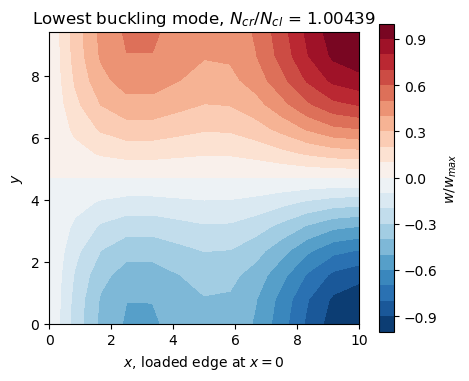

In [2]:
model = simo.SectionModel(12, 12)
eigvals, modes, ulin = simo.linear_buckling(model)
w = modes[6::10, 0].reshape(13, 13)
w /= w.flat[np.argmax(np.abs(w))]
fig, ax = plt.subplots(figsize=(5, 4))
cs = ax.contourf(model.x.reshape(13, 13), model.y.reshape(13, 13), w, 21,
                 cmap='RdBu_r')
fig.colorbar(cs, label='$w/w_{max}$')
ax.set_xlabel('$x$, loaded edge at $x = 0$')
ax.set_ylabel('$y$')
ax.set_aspect('equal')
ax.set_title('Lowest buckling mode, $N_{cr}/N_{cl}$ = %.5f' % eigvals[0])
plt.show()

## Initial imperfection, exactly for the Donnell-type kinematics

The element takes no initial geometric imperfection, but with the
Donnell-type kinematics an imperfection $w_0$ of the normal displacement
can be added exactly. In the strains of a shallow imperfect shell the
non-linear terms are $(w_{,x}^2 + 2 w_{0,x} w_{,x})/2$, ..., which are
those of $\boldsymbol{u} + \boldsymbol{u}_0$ minus those of
$\boldsymbol{u}_0$, with $\boldsymbol{u}_0$ the vector of the degrees of
freedom of $w_0$ ($u = v = 0$, $w = w_0$ with its derivatives); the linear
membrane strains and the curvatures are linear, so that

$$
\boldsymbol{\varepsilon}_{imp}(\boldsymbol{u}) =
\boldsymbol{\varepsilon}(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{\varepsilon}(\boldsymbol{u}_0), \qquad
\boldsymbol{\kappa}_{imp}(\boldsymbol{u}) =
\boldsymbol{\kappa}(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{\kappa}(\boldsymbol{u}_0) = \boldsymbol{\kappa}(\boldsymbol{u})
$$

and the imperfect shell is stress free at $\boldsymbol{u} = \boldsymbol{0}$.
Its stress resultants are those of the perfect shell at
$\boldsymbol{u} + \boldsymbol{u}_0$ minus $\boldsymbol{N}_0$ and
$\boldsymbol{M}_0$, those of the state $\boldsymbol{u}_0$, and since
$\boldsymbol{B}_{NL}(\boldsymbol{u} + \boldsymbol{u}_0) =
\boldsymbol{B}_{NL}(\boldsymbol{u}) + \boldsymbol{B}_{NL}(\boldsymbol{u}_0)$
and $\int_A \boldsymbol{B}_{NL}(\boldsymbol{u})^\top \boldsymbol{N}_0 dA =
\boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{u}$, the gradient of the
strain energy of the imperfect shell is

$$
\boldsymbol{F}_{int,imp}(\boldsymbol{u}) =
\boldsymbol{F}_{int}(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{F}_{int}(\boldsymbol{u}_0) -
\boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{u}, \qquad
\boldsymbol{K}_{T,imp}(\boldsymbol{u}) =
\boldsymbol{K}_T(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{K}_G(\boldsymbol{N}_0)
$$

with $\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_{GNL} + \boldsymbol{K}_G$ and
$\boldsymbol{K}_G(\boldsymbol{N}_0)$ the geometric stiffness matrix of the
resultants $\boldsymbol{N}_0$ of the **whole** strains of
$\boldsymbol{u}_0$, linear and non-linear. The identities hold for the
quadrature sums of the elements, for any number of integration points, when
$\boldsymbol{K}_G(\boldsymbol{N}_0)$ is integrated with the same points.

`update_KG` builds its matrix from the resultants of the linear strains
only, $\boldsymbol{K}_G(\boldsymbol{u}_0)$, which is linear in the
displacements, see its Notes; the part of the non-linear strains,
$\boldsymbol{K}_{GNL,0}$, is computed by `SectionModel.calc_kG_N` from the
resultants at the integration points, such that
$\boldsymbol{K}_G(\boldsymbol{N}_0) = \boldsymbol{K}_G(\boldsymbol{u}_0) +
\boldsymbol{K}_{GNL,0}$. The callables of structsolve, in
`ImperfectCylinder`, are then

- `calc_fint`: $\boldsymbol{F}_{int}(\boldsymbol{u} + \boldsymbol{u}_0) -
  \boldsymbol{F}_{int}(\boldsymbol{u}_0) - \boldsymbol{K}_G(\boldsymbol{u}_0)
  \boldsymbol{u} - \boldsymbol{K}_{GNL,0} \boldsymbol{u}$;
- `calc_kC`: $\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL}(\boldsymbol{u} +
  \boldsymbol{u}_0) + \boldsymbol{K}_{GNL}(\boldsymbol{u} + \boldsymbol{u}_0)
  - \boldsymbol{K}_{GNL,0}$, the matrix of `update_KCNL` minus
  $\boldsymbol{K}_{GNL,0}$;
- `calc_kG`: $\boldsymbol{K}_G(\boldsymbol{u} + \boldsymbol{u}_0) -
  \boldsymbol{K}_G(\boldsymbol{u}_0) = \boldsymbol{K}_G(\boldsymbol{u})$,
  the geometric stiffness matrix of the perfect shell.

The construction uses the Donnell-type element: `calc_kG_N` builds the
geometric stiffness matrix with the rows of $w_{,x}$ and $w_{,y}$ of the
Donnell-type kinematics. With the Sanders-type element the rotation is
$-w_{,y} + v/R$, its geometric stiffness matrix has rows in $v$, and these
identities, not verified here, would need that matrix for
$\boldsymbol{N}_0$.

The checks below, on a $4 \times 4$ mesh: the internal forces vanish at
$\boldsymbol{u} = \boldsymbol{0}$; `calc_kG_N` with the resultants of the
linear strains gives the matrix of `update_KG`; the tangent stiffness
matrix is the Jacobian of the internal forces, by central differences; and
the internal forces are the gradient of the strain energy of the strains
$\boldsymbol{\varepsilon}(\boldsymbol{u} + \boldsymbol{u}_0) -
\boldsymbol{\varepsilon}(\boldsymbol{u}_0)$, computed by
`SectionModel.strain_energy` from the interpolation of the element at the
integration points, independently of its kernels. The same gradient with
$\boldsymbol{K}_G(\boldsymbol{u}_0)$ alone in place of
$\boldsymbol{K}_G(\boldsymbol{N}_0)$ is off by orders of magnitude more
than the error of the central differences, which decreases with $h^2$.

In [3]:
rng = np.random.default_rng(1)
model, mode, lbd_cr = simo.normalized_model(4, 4)
n = model.bu.sum()
u = model.expand(rng.standard_normal(n)*1e-2)
KG = model.calc_KG(u).toarray()
KGN = model.calc_kG_N(model.membrane_resultants(u, nonlinear=False)).toarray()
print('calc_kG_N(N_L(u)) vs. update_KG(u): rel. diff %.1e'
      % (np.abs(KGN - KG).max()/np.abs(KG).max()))
for xi in (0.1, 0.5):
    u0 = simo.imperfection(model, mode, xi)
    imp = simo.ImperfectCylinder(model, u0)
    print('imperfection %g t: |F_int,imp(0)| = %.1e' %
          (xi, np.linalg.norm(imp.calc_fint(np.zeros(n)))))
    u = np.zeros(model.N)
    u[6::10] = rng.standard_normal(model.N//10)
    u *= 0.3*simo.t/np.abs(u).max()
    u[0::10] = 1e-3*rng.standard_normal(model.N//10)
    u[3::10] = 1e-3*rng.standard_normal(model.N//10)
    c = u[model.bu]
    U = model.expand(c)
    v = rng.standard_normal(n)
    KT = imp.calc_kC(c, NLgeom=True) + imp.calc_kG(c, NLgeom=True)
    fv = imp.calc_fint(c) @ v
    fv_L = (model.calc_fint(U + u0) - imp.fint0 - imp.KG0 @ U)[model.bu] @ v
    for h in (1e-4, 1e-5):
        dfd = (imp.calc_fint(c + h*v) - imp.calc_fint(c - h*v))/(2*h)
        dU = (model.strain_energy(model.expand(c + h*v), u0)
              - model.strain_energy(model.expand(c - h*v), u0))/(2*h)
        print('  h = %.0e: tangent %.1e, energy gradient %.1e, '
              'with K_G(u0) alone %.1e'
              % (h, np.linalg.norm(dfd - KT @ v)/np.linalg.norm(KT @ v),
                 abs(dU - fv)/abs(fv), abs(dU - fv_L)/abs(fv)))

calc_kG_N(N_L(u)) vs. update_KG(u): rel. diff 5.2e-16
imperfection 0.1 t: |F_int,imp(0)| = 0.0e+00
  h = 1e-04: tangent 8.0e-09, energy gradient 2.8e-06, with K_G(u0) alone 3.3e-05
  h = 1e-05: tangent 8.0e-11, energy gradient 2.8e-08, with K_G(u0) alone 3.6e-05
imperfection 0.5 t: |F_int,imp(0)| = 0.0e+00
  h = 1e-04: tangent 1.2e-08, energy gradient 4.0e-06, with K_G(u0) alone 1.5e-04
  h = 1e-05: tangent 1.2e-10, energy gradient 4.0e-08, with K_G(u0) alone 1.4e-04


## Riks analyses with the imperfections

The imperfection is the $w$ part of the lowest buckling mode, scaled to a
largest $|w_0|$ of 10 % or 50 % of $t$. Its sign does not matter: the
section is symmetric about $y = b/2$, and $-\cos(\pi y/b) = \cos(\pi (b -
y)/b)$. The reference load of each mesh is its own linear buckling load,
such that the load factor of structsolve is the normalized load of the
figure. The Riks method of structsolve starts with an increment of 0.1 of
the load factor, limited to 0.1, and stops at the first converged increment
with a maximum axial deflection of 0.04, with `stop_criterion =
value_reached(...)` (`run_riks` of the module). Three meshes, the finest
one, $12 \times 12$, being the one of the figures:

In [4]:
runs = {}
for xi in (0.1, 0.5):
    for n in (4, 8, 12):
        r = simo.run_riks(xi, n, n)
        runs[xi, n] = r
        an = r['an']
        fext = an.calc_fext()
        res = max(np.linalg.norm(an.calc_fint(c) - lbd*fext)
                  for lbd, c in zip(an.increments, an.cs))/np.linalg.norm(fext)
        lbd_lim, u_lim = simo.limit_point(r['lbds'], r['umax'])
        print('%2d %% %2d x %2d: N_cr/N_cl %.5f, %3d increments, %5.1f s, '
              'max. residual %.0e, limit load %.4f at u_max %.5f'
              % (100*xi, n, n, r['lbd_cr'], len(an.increments), r['elapsed'],
                 res, lbd_lim, u_lim))

10 %  4 x  4: N_cr/N_cl 1.01100, 102 increments,   4.6 s, max. residual 8e-11, limit load 0.7294 at u_max 0.01657


10 %  8 x  8: N_cr/N_cl 1.00491, 101 increments,  18.3 s, max. residual 1e-10, limit load 0.7270 at u_max 0.01625


10 % 12 x 12: N_cr/N_cl 1.00439, 100 increments,  46.8 s, max. residual 1e-10, limit load 0.7269 at u_max 0.01625


50 %  4 x  4: N_cr/N_cl 1.01100,  65 increments,   4.3 s, max. residual 2e-10, limit load 0.3965 at u_max 0.01064


50 %  8 x  8: N_cr/N_cl 1.00491,  64 increments,  14.3 s, max. residual 2e-10, limit load 0.3905 at u_max 0.01070


50 % 12 x 12: N_cr/N_cl 1.00439,  64 increments,  40.4 s, max. residual 2e-10, limit load 0.3902 at u_max 0.01070


The limit loads change by less than 0.001 from the $8 \times 8$ to the $12
\times 12$ mesh; a $16 \times 16$ mesh, not run here (77 s and 52 s), gives
0.7270 and 0.3902, at the same deflections within $10^{-5}$. The residual
of every converged increment is below $10^{-9}$ of the reference load
vector.

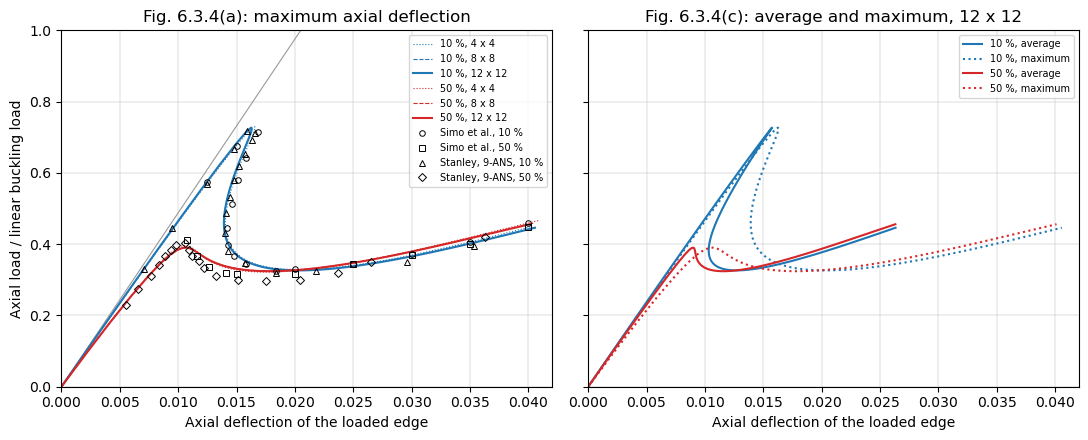

In [5]:
def plot_fig(ax, data, marker, label):
    d = np.array(data)
    ax.plot(d[:, 0], d[:, 1], marker, ms=4, mfc='none', color='k', mew=0.7,
            label=label)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colors = {0.1: 'C0', 0.5: 'C3'}
ax = axes[0]
ax.plot([0, 0.04], [0, 0.04/simo.FIG_LINEAR_U1], color='0.6', lw=0.8)
for xi in (0.1, 0.5):
    for n, ls, lw in ((4, ':', 0.8), (8, '--', 0.8), (12, '-', 1.5)):
        r = runs[xi, n]
        ax.plot(r['umax'], r['lbds'], ls=ls, lw=lw, color=colors[xi],
                label='%d %%, %d x %d' % (100*xi, n, n))
plot_fig(ax, simo.FIG_A_SIMO_10, 'o', 'Simo et al., 10 %')
plot_fig(ax, simo.FIG_A_SIMO_50, 's', 'Simo et al., 50 %')
plot_fig(ax, simo.FIG_A_ANS_10, '^', 'Stanley, 9-ANS, 10 %')
plot_fig(ax, simo.FIG_A_ANS_50, 'D', 'Stanley, 9-ANS, 50 %')
ax.set_title('Fig. 6.3.4(a): maximum axial deflection')
ax.set_ylabel('Axial load / linear buckling load')
ax = axes[1]
for xi in (0.1, 0.5):
    r = runs[xi, 12]
    ax.plot(r['uavg'], r['lbds'], '-', color=colors[xi],
            label='%d %%, average' % (100*xi))
    ax.plot(r['umax'], r['lbds'], ':', color=colors[xi],
            label='%d %%, maximum' % (100*xi))
ax.set_title('Fig. 6.3.4(c): average and maximum, 12 x 12')
for ax in axes:
    ax.set_xlim(0, 0.042)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Axial deflection of the loaded edge')
    ax.grid(lw=0.3)
    ax.legend(fontsize=7, loc='upper right')
fig.tight_layout()
plt.show()

The values of Simo et al. and of Stanley are read from Fig. 6.3.4 on the
page rendered at 300 dpi with a grid of $0.001 \times 0.05$ drawn over the
axes, to about $\pm 0.0003$ in the deflection and $\pm 0.01$ in the load.
The table compares the limit loads, the minimum loads after them and the
loads at a maximum deflection of 0.04, of the $12 \times 12$ mesh:

In [6]:
def summary(r):
    lbds, u = r['lbds'], r['umax']
    ilim = np.flatnonzero(np.diff(lbds) < 0)[0]
    imin = ilim + np.argmin(lbds[ilim:])
    p04 = np.interp(0.04, u[-2:], lbds[-2:])
    return lbds[ilim], u[ilim], lbds[imin], u[imin], p04


def fig_summary(data):
    d = np.array(data)
    ilim = np.flatnonzero(np.diff(d[:, 1]) < 0)[0]
    imin = ilim + np.argmin(d[ilim:, 1])
    p04 = d[-1, 1] if abs(d[-1, 0] - 0.04) < 1e-4 else np.nan
    return d[ilim, 1], d[ilim, 0], d[imin, 1], d[imin, 0], p04


print('%-26s %7s %8s %7s %8s %7s' % ('', 'P_lim', 'u_lim', 'P_min', 'u_min',
                                     'P(0.04)'))
for xi, fsimo, fans in ((0.1, simo.FIG_A_SIMO_10, simo.FIG_A_ANS_10),
                        (0.5, simo.FIG_A_SIMO_50, simo.FIG_A_ANS_50)):
    for label, s in (('BFSC 12 x 12, %d %%' % (100*xi), summary(runs[xi, 12])),
                     ('Simo et al., Fig. (a)', fig_summary(fsimo)),
                     ('Stanley 9-ANS, Fig. (a)', fig_summary(fans))):
        print('%-26s %7.3f %8.4f %7.3f %8.4f %7.3f' % ((label,) + s))

                             P_lim    u_lim   P_min    u_min P(0.04)
BFSC 12 x 12, 10 %           0.727   0.0163   0.326   0.0203   0.441
Simo et al., Fig. (a)        0.715   0.0168   0.326   0.0184   0.459
Stanley 9-ANS, Fig. (a)      0.717   0.0159   0.319   0.0184     nan
BFSC 12 x 12, 50 %           0.390   0.0107   0.324   0.0179   0.455
Simo et al., Fig. (a)        0.411   0.0108   0.315   0.0150   0.449
Stanley 9-ANS, Fig. (a)      0.402   0.0106   0.297   0.0175     nan


The limit loads are 0.727 and 0.390, against 0.715 and 0.411 of Simo et
al. and 0.717 and 0.402 of Stanley's 9-ANS element, at deflections within
0.0006 of theirs. The differences, 0.012 and 0.021, are larger than the
reading precision, and of the size of the differences between the two
elements of the figure; the Donnell-type kinematics of this model and the
geometrically exact shell of [1] differ in the terms of the order of the
waves over the radius, and their $10 \times 10$ mesh of a low-order element
is coarser than the converged meshes here. The post-buckling path is that
of the figure: the load drops at a decreasing, then increasing, deflection
to a minimum of 0.326 (10 %) and 0.324 (50 %), against 0.326 and 0.315 of
Simo et al., and both curves rise again to 0.44-0.46 at a deflection of
0.04 (0.459 and 0.449 in the figure). The average deflection, Fig.
6.3.4(c), is smaller than the maximum one beyond the limit point, the
section shortening most at the inward lobe of the mode.

The Riks analyses of a Ritz model of the same section with panels, in the
benchmark `benchmarks/simo1990_cylinder.py` of structsolve, give 1.00415
$N_{cl}$ for the buckling load, and limit loads of 0.727 at 0.0163 and 0.390
at 0.0107, the same as here to the digits given.

## The perfect cylinder, branch switching

Without imperfection the path is axisymmetric until a bifurcation. Fig.
6.3.4(d) traces it with a branch switching technique; [1] notes the
difficulties of a multiplicity of clustered critical points near the first
bifurcation, the solution process often changing paths. Here the Riks
method of structsolve runs with `inertia=True` and SuperLU, whose sign of
the determinant of the tangent stiffness matrix locates the critical points
crossed, and with `branch_switching=3`, which switches to the bifurcated
branch, along the critical eigenvector, at most three times. Increments of
at most 0.03 avoid stepping over the clustered critical points. The
$8 \times 8$ mesh:

In [7]:
r0 = simo.run_riks(0., 8, 8, branch_switching=3)
an0 = r0['an']
bp = np.array(an0.branch_points)
print('%d increments, %.0f s, switched at the increments %s, of load '
      'factor %s, maximum deflection %s'
      % (len(an0.increments), r0['elapsed'], bp,
         np.array2string(r0['lbds'][bp + 1], precision=4),
         np.array2string(r0['umax'][bp + 1], precision=5)))
signs = np.array(an0.det_signs)
print('sign of the determinant: +1 up to the increment %d, then %s'
      % (np.argmax(signs < 0) - 1, np.unique(signs[np.argmax(signs < 0):])))
lbds0, u0max = r0['lbds'], r0['umax']
ilim = bp[0] + 1
imin = ilim + np.argmin(lbds0[ilim:])
print('bifurcation %.4f at %.5f; minimum %.4f at %.5f; %.4f at 0.04'
      % (lbds0[ilim], u0max[ilim], lbds0[imin], u0max[imin],
         np.interp(0.04, u0max[-2:], lbds0[-2:])))

461 increments, 126 s, switched at the increments [33], of load factor [0.8241], maximum deflection [0.01815]
sign of the determinant: +1 up to the increment 32, then [-1  1]
bifurcation 0.8241 at 0.01815; minimum 0.3272 at 0.02091; 0.4384 at 0.04


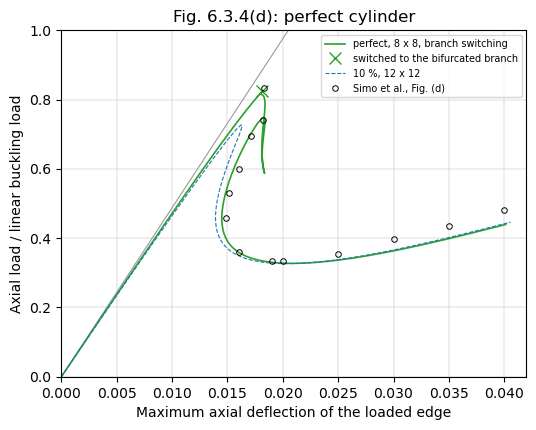

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 0.04], [0, 0.04/simo.FIG_LINEAR_U1], color='0.6', lw=0.8)
ax.plot(u0max, lbds0, '-', color='C2', lw=1.2,
        label='perfect, 8 x 8, branch switching')
ax.plot(u0max[bp + 1], lbds0[bp + 1], 'x', color='C2', ms=8,
        label='switched to the bifurcated branch')
ax.plot(runs[0.1, 12]['umax'], runs[0.1, 12]['lbds'], '--', color='C0',
        lw=0.8, label='10 %, 12 x 12')
plot_fig(ax, simo.FIG_D_SIMO, 'o', 'Simo et al., Fig. (d)')
ax.set_xlim(0, 0.042)
ax.set_ylim(0, 1)
ax.set_xlabel('Maximum axial deflection of the loaded edge')
ax.set_ylabel('Axial load / linear buckling load')
ax.set_title('Fig. 6.3.4(d): perfect cylinder')
ax.grid(lw=0.3)
ax.legend(fontsize=7, loc='upper right')
plt.show()

The sign of the determinant changes on the axisymmetric path between the
increments 32 and 33, where the analysis switches to the bifurcated branch,
at a load of 0.824 and a maximum deflection of 0.0181, against 0.833 and
0.0183 read from Fig. 6.3.4(d); the bifurcation is below the linear
buckling load because of the non-linear axisymmetric pre-buckling state at
the simple support. On the bifurcated branch the load first falls at an
almost constant maximum deflection, 0.0179 to 0.0184, as in the figure,
down to a limit point at 0.587, rises to another one at 0.748 and then
falls with a decreasing maximum deflection, 0.0145 at a load of 0.45
(0.0149 at 0.457 in the figure), to the minimum, 0.327 at 0.0209 (0.334
at 0.020), and ends on the curve of the 10 % imperfection, 0.438 at 0.04
(0.480 in the figure). The sign of the determinant changes at each of
these three limit points of the branch, such that the analysis crosses no
other bifurcation than the first, and it needed one switch only of the
three allowed, in about 460 increments. Between the bifurcation and the
descent the figure has a drop to about 0.74 followed by a dotted excursion
to a deflection of about 0.0195, of a path that, according to [1], changes
branches near clustered critical points; this part of the path differs
from the loop computed here, and only the bifurcation load, the descent,
the minimum and the end of the curves are compared.

## References

[1] Simo, J. C., Fox, D. D., and Rifai, M. S., On a stress resultant
geometrically exact shell model. Part III: Computational aspects of the
nonlinear theory, Computer Methods in Applied Mechanics and Engineering,
79(1), 21-70, 1990, doi:10.1016/0045-7825(90)90094-3.

[2] Stanley, G. M., Continuum-based shell elements, PhD thesis, Stanford
University, 1985.